In [1]:
import wandb
import pandas as pd
api = wandb.Api()

wandb: [wandb.Api()] Loaded credentials for https://api.wandb.ai from /home/pipev/.netrc.


In [2]:
runs = api.runs("pipe-verri-gh/Canonicalization", filters={
    "jobType": "finetuning",
    "group": "pretraining_baseline"
})

In [30]:
df = pd.DataFrame([
    run.summary._json_dict | {
        "name": run.name,
        "id": run.id,
        "tags": run.tags,
        "downstream_task": run.config.get("dataset", {}).get("dataset_name"),
    }
    for run in runs
])

In [31]:
old = df[df["tags"].apply(lambda t: "old_code" in t)]
new = df[df["tags"].apply(lambda t: "old_code" not in t)]

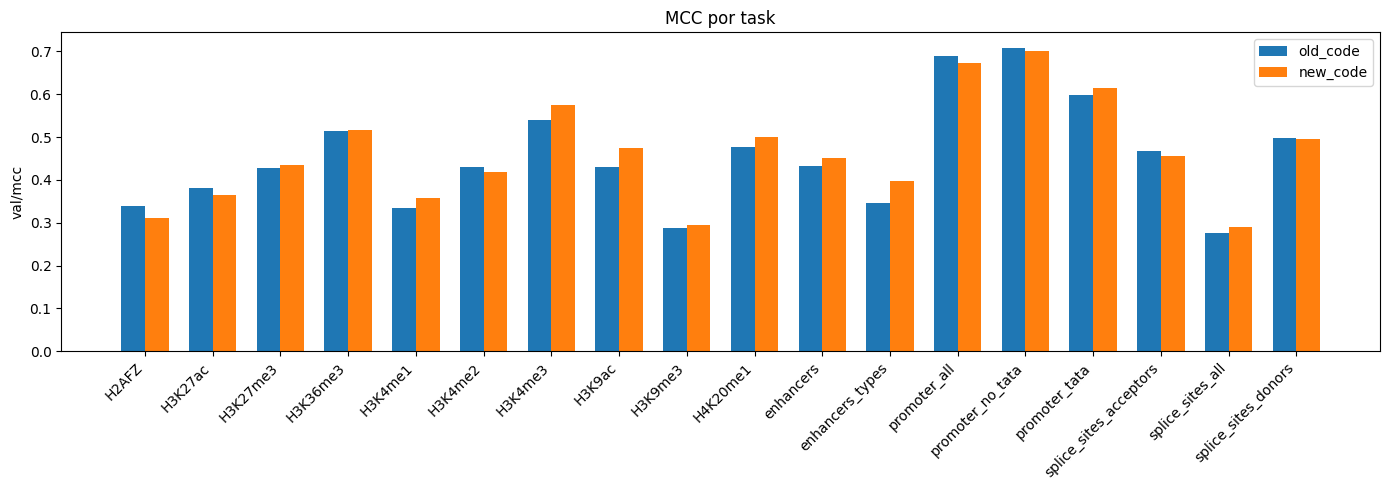

In [33]:
import matplotlib.pyplot as plt
import numpy as np

# Alinear por task (asumiendo que tenés una columna "task")
tasks = sorted(df["downstream_task"].unique())
old_vals = [old[old["downstream_task"] == t]["val/mcc"].values[0] for t in tasks]
new_vals = [new[new["downstream_task"] == t]["val/mcc"].values[0] for t in tasks]

# Plot
x = np.arange(len(tasks))
width = 0.35

fig, ax = plt.subplots(figsize=(14, 5))
ax.bar(x - width/2, old_vals, width, label="old_code")
ax.bar(x + width/2, new_vals, width, label="new_code")

ax.set_xticks(x)
ax.set_xticklabels(tasks, rotation=45, ha="right")
ax.set_ylabel("val/mcc")
ax.set_title("MCC por task")
ax.legend()

plt.tight_layout()
plt.show()

In [36]:
old_wins = 0
new_wins = 0

for old_val, new_val in zip(old_vals, new_vals):
    if old_val > new_val:
        old_wins += 1
    else:
        new_wins += 1

print(f"Old code surpasses {old_wins} times")
print(f"New code surpasses {new_wins} times")

Old code surpasses 7 times
New code surpasses 11 times
